# assignment 1
Please select one city in the U.S. and generate the NDVI map and the vegetation cover map at the census tract level.
1. Collect the city limit file for the city (hint: reproject it into wgs 84 projection, epsg code of 4326 using QGIS).
2. Download the NAIP tiles and mosaic them.
3. Mask out those pixels outside the bounds.
4. Calculate the NDVI and vegetation cover map (hint: you can use a threshold of 0.1 to separate vegetation and non-vegetation based on NDVI).
5. Generate the census tract-level map of NDVI and vegetation cover (hint: make sure the projection of the shapefile and raster matched; reproject the shapefile to the same projection as your raster data, because it is easier to reproject a shapefile)

## Download, merge, and clip

In [1]:
# --- standard library ---------------------------------------------------
import os
import os.path
import glob
import urllib.request                      # downloads a URL to a local file

# --- searching and signing the Planetary Computer catalog ---------------
import pystac_client                       # STAC API client: search for imagery
import planetary_computer as pc            # signs Microsoft's asset URLs

# --- raster and vector I/O ----------------------------------------------
import rasterio as rio                     # read/write GeoTIFFs
import fiona                               # read/write vector files (shapefiles)
import geopandas as gpd                    # vector data as a table (used for a quick map)

# --- geometry and arrays -------------------------------------------------
import numpy as np
from shapely.geometry import shape, box, mapping   # build/convert geometries

# --- plotting -------------------------------------------------------------
from matplotlib import pyplot as plt

from dotenv import load_dotenv
load_dotenv()

print("pystac_client:", pystac_client.__version__)

pystac_client: 0.9.0


In [2]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,   # every asset URL comes back ready to download
)

catalog

<Client id=microsoft-pc>

In [3]:
shpfile = 'sf_boundary\\sf_place_tl_2024_06.shp'

# fiona opens a vector file as a stream of features. Using `with` closes it for us.
with fiona.open(shpfile) as lyr:
    print("CRS of the input file:", lyr.crs.to_string())   # must be EPSG:4326
    print("Number of features   :", len(lyr))

    # Convert every feature to a shapely geometry. Keeping them in a list (rather
    # than merging them) means this works for a boundary made of several polygons.
    city_parts = [shape(feat['geometry']) for feat in lyr]

    # .bounds gives the extent of the whole layer: (minx, miny, maxx, maxy)
    left, bottom, right, top = lyr.bounds

print("\nBounding box (lon/lat):", (left, bottom, right, top))

# shapely's box() builds the rectangle; mapping() converts it to the GeoJSON dict
# that the STAC API expects.
area_of_interest = mapping(box(left, bottom, right, top))
area_of_interest

CRS of the input file: EPSG:4326
Number of features   : 1

Bounding box (lon/lat): (-122.61229824899999, 37.706725927000036, -122.28179318699995, 37.92982895600005)


{'type': 'Polygon',
 'coordinates': (((-122.28179318699995, 37.706725927000036),
   (-122.28179318699995, 37.92982895600005),
   (-122.61229824899999, 37.92982895600005),
   (-122.61229824899999, 37.706725927000036),
   (-122.28179318699995, 37.706725927000036)),)}

In [7]:
startDate = '2022-01-01'
endDate   = '2022-12-31'
range_time = f"{startDate}/{endDate}"     # STAC wants a single "START/END" string

search = catalog.search(
    collections=["naip"],          # which dataset
    intersects=area_of_interest,   # where  (GeoJSON geometry, EPSG:4326)
    datetime=range_time,           # when
)

# .item_collection() actually sends the request and pages through all the results.
# (Older tutorials call .get_items() -- that name is deprecated.)
items_tiles = search.item_collection()

print(f"{len(items_tiles)} NAIP tiles found for {range_time}")

22 NAIP tiles found for 2022-01-01/2022-12-31


In [8]:
# Look at a single Item to see what the catalog knows about it
item = items_tiles[0]

print("id       :", item.id)
print("date     :", item.datetime.date())
print("state    :", item.properties.get("naip:state"))
print("gsd      :", item.properties.get("gsd"), "m per pixel")
print("assets   :", list(item.assets))
print("\nimage href (signed, truncated):")
print(item.assets["image"].href[:120], "...")

id       : ca_m_3712220_ne_10_060_20220519
date     : 2022-05-19
state    : ca
gsd      : 0.6 m per pixel
assets   : ['image', 'thumbnail', 'tilejson', 'rendered_preview']

image href (signed, truncated):
https://naipeuwest.blob.core.windows.net/naip/v002/ca/2022/ca_060cm_2022/37122/m_3712220_ne_10_060_20220519.tif?st=2026- ...


In [12]:
outfolder = 'cir-naip'
os.makedirs(outfolder, exist_ok=True)   # exist_ok=True: no error if it is already there

MAX_TILES = None      # set to e.g. 2 to try the workflow out without an 8 GB download
to_download = items_tiles[:MAX_TILES] if MAX_TILES else items_tiles

for n, item in enumerate(to_download, start=1):
    outfilename = os.path.join(outfolder, item.id + ".tif")

    # Already have it? Move on. This is what makes the cell safe to re-run.
    if os.path.exists(outfilename):
        print(f"[{n}/{len(to_download)}] {item.id} -- already on disk, skipping")
        continue

    # The href is already signed, because we opened the catalog with sign_inplace
    unsigned_href = item.assets["image"].href.split("?", 1)[0]
    href = pc.sign(unsigned_href)
 
    print(f"[{n}/{len(to_download)}] downloading {item.id} ...")
    urllib.request.urlretrieve(href, outfilename)

print("\nDone.")

[1/22] ca_m_3712220_ne_10_060_20220519 -- already on disk, skipping
[2/22] ca_m_3712212_se_10_060_20220519 -- already on disk, skipping
[3/22] ca_m_3712212_nw_10_060_20220519 -- already on disk, skipping
[4/22] ca_m_3712212_ne_10_060_20220519 -- already on disk, skipping
[5/22] ca_m_3712204_sw_10_060_20220519 -- already on disk, skipping
[6/22] downloading ca_m_3712204_se_10_060_20220519 ...
[7/22] downloading ca_m_3712222_nw_10_060_20220518 ...
[8/22] downloading ca_m_3712222_ne_10_060_20220518 ...
[9/22] downloading ca_m_3712221_nw_10_060_20220518 ...
[10/22] downloading ca_m_3712221_ne_10_060_20220518 ...
[11/22] downloading ca_m_3712214_sw_10_060_20220518 ...
[12/22] downloading ca_m_3712214_se_10_060_20220518 ...
[13/22] downloading ca_m_3712214_nw_10_060_20220518 ...
[14/22] downloading ca_m_3712214_ne_10_060_20220518 ...
[15/22] downloading ca_m_3712213_sw_10_060_20220518 ...
[16/22] downloading ca_m_3712213_se_10_060_20220518 ...
[17/22] downloading ca_m_3712213_nw_10_060_20220

In [14]:
# This function is used to mosaic geotiffs in the input folder
# Parameters:
#     dirpath: the folder name of the tif files
#     outfile: the output file of the mosaiced geotiff image

import rasterio
# import ogr
import fiona
import os, os.path
from rasterio.merge import merge
import glob
from shapely.geometry import Polygon
from shapely.geometry import shape


# mosaicRasters(folder, os.path.join(root, 'naip-atlanta.tif'))
inputfolder= 'cir-naip'
outfile = 'data/mosacied-naip.tif'

# start to mosaic the raster tiles
tiflist = []

for file in os.listdir(inputfolder):    
    if file.endswith('.tif'):
        tiffile = os.path.join(inputfolder, file)
        tiflist.append(tiffile)


src_files_to_mosaic = []
for fp in tiflist:
    try:
        tile_src = rasterio.open(fp)
        tile_bounds = tile_src.bounds
        
        src_files_to_mosaic.append(tile_src)
    except:
        continue

print('The number of mosaiced tiles is:', len(src_files_to_mosaic))

# the method can be set as min, max..
mosaic, out_trans = merge(src_files_to_mosaic) #, method='max'
print('You have mosaiced the results')


# Prepare the schema of the output mosacied image
out_meta = tile_src.meta.copy()
out_meta.update({"driver": "GTiff",
                  "height": mosaic.shape[1],
                  "width": mosaic.shape[2],
                  "transform": out_trans, 
                  "compress": 'lzw',
                  'BIGTIFF': 'YES'
                  }
               )

#out_fp = os.path.join(dirpath, 'atlanta-naip.tif')
with rasterio.open(outfile, "w", **out_meta) as dest:
     dest.write(mosaic)


The number of mosaiced tiles is: 22
You have mosaiced the results


In [16]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask

input_value_raster = 'data/mosacied-naip.tif'
shpfile = 'sf_boundary/sf_place_tl_2024_06.shp'
out_raster = 'data/maskSF-naip.tif'

city = gpd.read_file(shpfile)

with rasterio.open(input_value_raster) as src:
    city_proj = city.to_crs(src.crs)
    shapes = list(city_proj.geometry)

    out_image, out_transform = mask(src, shapes, crop=True)
    out_meta = src.meta.copy()

out_meta.update({
    "driver": "GTiff",
    "height": out_image.shape[1],
    "width": out_image.shape[2],
    "transform": out_transform,
    "compress": "lzw",
    "BIGTIFF": "IF_SAFER"
})

with rasterio.open(out_raster, "w", **out_meta) as dest:
    dest.write(out_image)

## vegetation cover

In [2]:
from pathlib import Path
import math
import numpy as np
import geopandas as gpd
import rasterio as rio
from rasterio.windows import Window
from rasterio.features import geometry_mask, geometry_window
from rasterio.errors import WindowError
from shapely.geometry import mapping
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap

work = Path.cwd()
if not (work / 'sf_boundary').exists():
    work = work / 'assignment' / 'assignment_1'
data = work / 'data'
data.mkdir(exist_ok=True)
naip_file = data / 'maskSF-naip.tif'
ndvi_file = data / 'ndviSF.tif'
veg_file = data / 'vegSF.tif'
city_file = work / 'sf_boundary' / 'sf_place_tl_2024_06.shp'
threshold = 0.1
block_size = 1024
ndvi_nodata = -9999.0
veg_nodata = 255 

def windows_in(width, height, col_start=0, row_start=0):
    for row in range(row_start, row_start + height, block_size):
        for col in range(col_start, col_start + width, block_size):
            yield Window(col, row,
                         min(block_size, col_start + width - col),
                         min(block_size, row_start + height - row))

city = gpd.read_file(city_file)
with rio.open(naip_file) as src:
    if src.crs is None or src.count < 4:
        raise ValueError('The input needs a CRS and four RGB+NIR bands.')
    city_proj = city.to_crs(src.crs)  
    city_shapes = [mapping(g) for g in city_proj.geometry]
    print('Raster:', src.crs, src.width, src.height, 'resolution:', src.res)



Raster: EPSG:26910 48637 41367 resolution: (0.6, 0.6)


In [3]:
with rio.Env(GDAL_CACHEMAX=128 * 1024 * 1024):
    with rio.open(naip_file) as src:
        profile = dict(driver='GTiff', width=src.width, height=src.height,
                       count=1, crs=src.crs, transform=src.transform,
                       tiled=True, blockxsize=512, blockysize=512,
                       compress='lzw', BIGTIFF='YES')
        total = math.ceil(src.width / block_size) * math.ceil(src.height / block_size)
        with rio.open(ndvi_file, 'w', **profile, dtype='float32',
                      nodata=ndvi_nodata) as ndvi_dst, \
             rio.open(veg_file, 'w', **profile, dtype='uint8',
                      nodata=veg_nodata) as veg_dst:
            for index, window in enumerate(windows_in(src.width, src.height), 1):
                red = src.read(1, window=window, masked=True).astype('float32')
                nir = src.read(4, window=window, masked=True).astype('float32')
                inside = geometry_mask(city_shapes, out_shape=red.shape,
                                       transform=src.window_transform(window),
                                       invert=True, all_touched=False)
                denominator = nir.data + red.data
                valid = (inside & ~np.ma.getmaskarray(red) & ~np.ma.getmaskarray(nir)
                         & np.isfinite(denominator) & (denominator > 0))
                ndvi = np.full(red.shape, ndvi_nodata, dtype='float32')
                np.divide(nir.data - red.data, denominator, out=ndvi, where=valid)
                veg = np.full(red.shape, veg_nodata, dtype='uint8')
                veg[valid] = (ndvi[valid] > threshold).astype('uint8')
                ndvi_dst.write(ndvi, 1, window=window)
                veg_dst.write(veg, 1, window=window)
                if index % 100 == 0 or index == total:
                    print(f'Processed {index}/{total} windows')
            ndvi_dst.update_tags(description='NDVI=(NIR-Red)/(NIR+Red); NAIP 2022')
            veg_dst.update_tags(threshold=str(threshold), classes='0=non-vegetation;1=vegetation;255=NoData')



Processed 100/1968 windows
Processed 200/1968 windows
Processed 300/1968 windows
Processed 400/1968 windows
Processed 500/1968 windows
Processed 600/1968 windows
Processed 700/1968 windows
Processed 800/1968 windows
Processed 900/1968 windows
Processed 1000/1968 windows
Processed 1100/1968 windows
Processed 1200/1968 windows
Processed 1300/1968 windows
Processed 1400/1968 windows
Processed 1500/1968 windows
Processed 1600/1968 windows
Processed 1700/1968 windows
Processed 1800/1968 windows
Processed 1900/1968 windows
Processed 1968/1968 windows


### Raster map previews

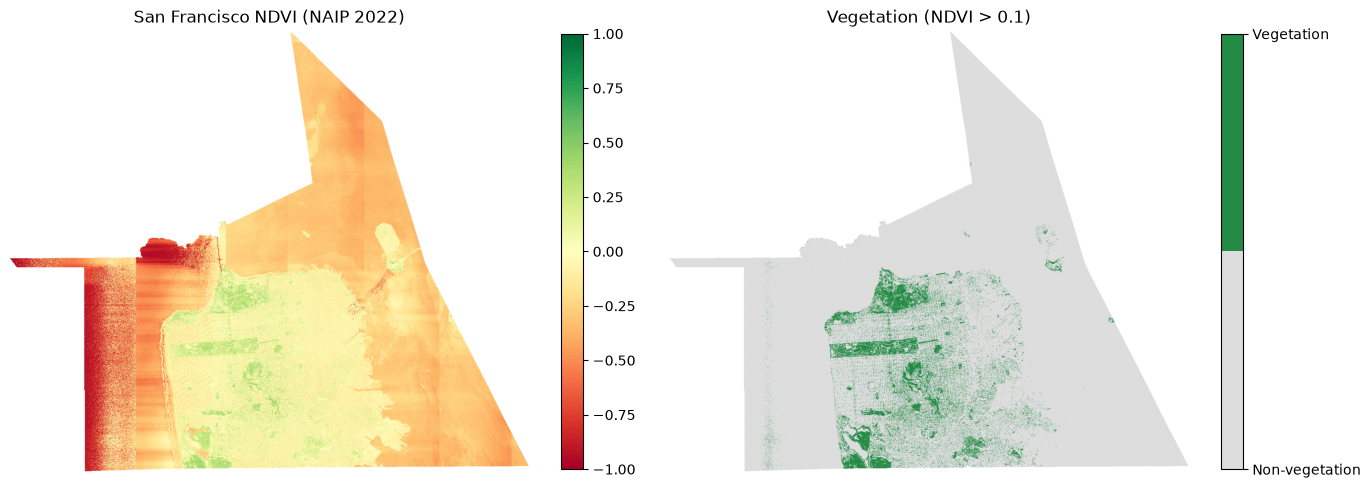

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for path, ax, title, cmap, low, high in [
    (ndvi_file, axes[0], 'San Francisco NDVI (NAIP 2022)', 'RdYlGn', -1, 1),
    (veg_file, axes[1], 'Vegetation (NDVI > 0.1)', ListedColormap(['#dddddd', '#238b45']), 0, 1)
]:
    with rio.open(path) as src:
        scale = max(src.width, src.height) / 1600
        preview = src.read(1, out_shape=(max(1, int(src.height / max(1, scale))),
                                         max(1, int(src.width / max(1, scale)))), masked=True)
    im = ax.imshow(preview, cmap=cmap, vmin=low, vmax=high)
    ax.set_title(title)
    ax.set_axis_off()
    cb = fig.colorbar(im, ax=ax, shrink=0.65)
    if path == veg_file:
        cb.set_ticks([0, 1], labels=['Non-vegetation', 'Vegetation'])
fig.tight_layout()
fig.savefig(data / 'sf_raster_maps.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

### Census tract boundaries

In [5]:
import urllib.request

tract_zip = data / 'tl_2024_06_tract.zip'
if not tract_zip.exists():
    url = 'https://www2.census.gov/geo/tiger/TIGER2024/TRACT/tl_2024_06_tract.zip'
    temporary = tract_zip.with_suffix('.zip.part')
    urllib.request.urlretrieve(url, temporary)
    temporary.replace(tract_zip)  
tracts = gpd.read_file('zip://' + tract_zip.resolve().as_posix())
tracts = tracts.loc[(tracts['STATEFP'] == '06') & (tracts['COUNTYFP'] == '075')].copy()
tracts = tracts.to_crs(city_proj.crs)
city_geometry = city_proj.geometry.union_all()
tracts.geometry = tracts.geometry.intersection(city_geometry)
tracts = tracts.loc[~tracts.geometry.is_empty & tracts.geometry.area.gt(0)].copy()
tracts = tracts.reset_index(drop=True)

### Tract-level mean NDVI and vegetation percentage

In [ ]:
tracts['mean_ndvi'] = np.nan
tracts['veg_pct'] = np.nan
tracts['valid_n'] = np.int64(0)
tracts['zone_n'] = np.int64(0)
tracts['valid_frac'] = np.nan

with rio.Env(GDAL_CACHEMAX=128 * 1024 * 1024):
    with rio.open(ndvi_file) as src:
        for index, feature in tracts.iterrows():
            geom = mapping(feature.geometry)
            try:
                zone_window = geometry_window(src, [geom])
            except WindowError:
                continue
            count = 0
            vegetation_count = 0
            zone_count = 0
            ndvi_sum = 0.0
            for window in windows_in(int(zone_window.width), int(zone_window.height),
                                     int(zone_window.col_off), int(zone_window.row_off)):
                values = src.read(1, window=window, masked=True)
                inside = geometry_mask([geom], out_shape=values.shape,
                                       transform=src.window_transform(window),
                                       invert=True, all_touched=False)
                valid = inside & ~np.ma.getmaskarray(values) & np.isfinite(values.data)
                pixels = values.data[valid]
                zone_count += int(inside.sum())
                count += pixels.size
                ndvi_sum += pixels.sum(dtype='float64')
                vegetation_count += int(np.count_nonzero(pixels > threshold))
            tracts.loc[index, 'valid_n'] = count
            tracts.loc[index, 'zone_n'] = zone_count
            if zone_count:
                tracts.loc[index, 'valid_frac'] = count / zone_count
            if count:
                tracts.loc[index, 'mean_ndvi'] = ndvi_sum / count
                tracts.loc[index, 'veg_pct'] = 100 * vegetation_count / count
            if (index + 1) % 25 == 0 or index + 1 == len(tracts):
                print(f'Processed {index + 1}/{len(tracts)} tracts')

tracts.to_file(data / 'sf_tract_vegetation.gpkg', layer='tracts', driver='GPKG')
tracts[['GEOID', 'mean_ndvi', 'veg_pct', 'valid_n', 'zone_n', 'valid_frac']].to_csv(
    data / 'sf_tract_vegetation.csv', index=False)
display(tracts[['GEOID', 'mean_ndvi', 'veg_pct', 'valid_n', 'valid_frac']].head())

Processed 25/243 tracts
Processed 50/243 tracts
Processed 75/243 tracts
Processed 100/243 tracts
Processed 125/243 tracts
Processed 150/243 tracts
Processed 175/243 tracts
Processed 200/243 tracts
Processed 225/243 tracts
Processed 243/243 tracts


,GEOID,mean_ndvi,veg_pct,valid_n,valid_frac
0,06075020602,0.015222,24.661590,683565,1.0
1,06075017102,0.016322,24.681385,818544,1.0
2,06075012302,-0.077594,1.668008,257193,1.0
3,06075016801,-0.021174,11.325070,628782,1.0
4,06075011902,-0.062454,6.216634,258307,1.0


Tracts with no valid pixels: 0


### Census tract maps

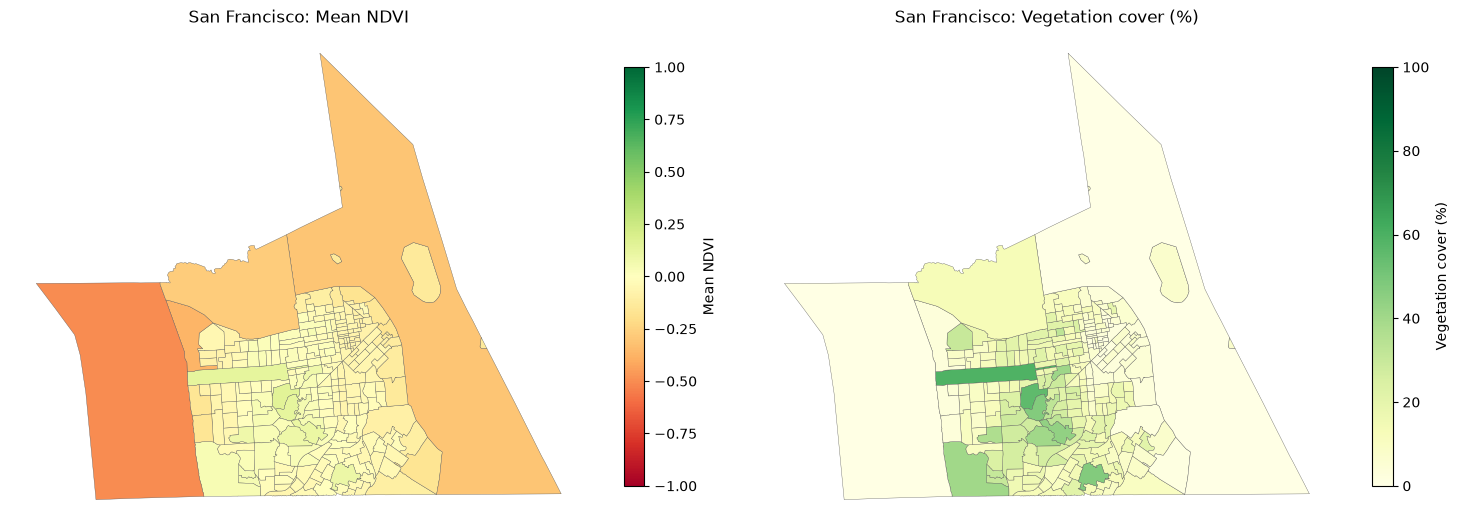

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, column, title, cmap, low, high in [
    (axes[0], 'mean_ndvi', 'Mean NDVI', 'RdYlGn', -1, 1),
    (axes[1], 'veg_pct', 'Vegetation cover (%)', 'YlGn', 0, 100)
]:
    tracts.plot(column=column, ax=ax, cmap=cmap, vmin=low, vmax=high,
                edgecolor='#555555', linewidth=0.25, legend=True,
                legend_kwds={'shrink': 0.6, 'label': title},
                missing_kwds={'color': '#dddddd', 'label': 'No valid data'})
    ax.set_title('San Francisco: ' + title)
    ax.set_axis_off()
fig.tight_layout(rect=[0, 0.04, 1, 0.95])
fig.savefig(data / 'sf_tract_maps.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)
